<div align="center">

# fse 101

Turn sentences into vectors, find similar text, and save your results.

</div>

## When do you need this?

You want to find related notes even when they use different words.
You have a list of messages to compare, or a file too large to encode in one call.
**Start here** before trying the other recipes.

## The story in pictures

![Sentences enter a model. Each becomes a row of numbers. Compare rows to find related text.](media/00-fse-101.svg)

A **sentence vector** is a list of numbers that represents a text.
Similar texts often have vectors that point in similar directions.
An **encoder** is the model that turns text into those vectors.
This recipe takes about 15 minutes to read, plus installation and download time.

## 1. Install fse

From a checkout of the development branch, run these commands in a terminal.
Use standard Python 3.13, rather than a free-threaded build.
The [recipe index](README.md#run-a-recipe) explains the shared setup.

```sh
UV_PYTHON=3.13 make install
uv pip install --python .venv/bin/python -r recipes/requirements.txt
```

Open this recipe with that environment's Python kernel.

## 2. Load a real model

POTION-base-8M is a small English **static model**, with a fixed vector for each word or word piece.
The first load downloads the model from the Hugging Face Hub.
The helper only manages temporary files and disables third-party telemetry.

In [1]:
from _helpers import Recipe
import fse
import numpy as np

recipe = Recipe()
work = recipe.work

Recipe run: 2026-11-01. Generated files are temporary.
Apple M1 Pro. macOS-27.0.1-arm64-arm-64bit-Mach-O. Python 3.13.16.


A model revision identifies the exact files used for a run.
Pin that revision so this recipe loads the same model next time.

In [2]:
import fse
from _helpers import POTION, POTION_REVISION

encoder = fse.Encoder.from_pretrained(
    POTION,
    revision=POTION_REVISION,
    cache_dir=work / "hub",
    token=False,
)
print("Numbers in each vector:", encoder.output_dim)

/Users/oliverborchers/.herdr/worktrees/Fast_Sentence_Embeddings/dr195-tutorials/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Numbers in each vector: 256


## 3. Encode a few sentences

Give the encoder a list of texts.
The result is a NumPy matrix, a table with **one row per text**.

In [3]:
texts = [
    "A cat is sleeping on the sofa.",
    "A kitten is resting on the couch.",
    "The train leaves the station at noon.",
    "A chef is preparing dinner in the kitchen.",
]
vectors = encoder.encode(texts, workers=1)
print("Matrix shape:", vectors.shape)
print("First five numbers:", vectors[0, :5].round(3))

Matrix shape: (4, 256)
First five numbers: [-0.068 -0.058 -0.02  -0.036 -0.199]


## Compare two sentences

Cosine similarity measures how closely two vectors point in the same direction.
These vectors have unit length, so their dot product gives that score.
**A higher score means more similar directions**, not a probability.

In [4]:
related = float(vectors[0] @ vectors[1])
unrelated = float(vectors[0] @ vectors[2])
print(f"Cat and kitten: {related:.3f}")
print(f"Cat and train:  {unrelated:.3f}")
assert related > unrelated

Cat and kitten: 0.715
Cat and train:  0.080


## 4. Try two million real sentences

[WikiText-103](https://huggingface.co/datasets/Salesforce/wikitext) contains Wikipedia text with CC BY-SA and GFDL terms listed in its pinned dataset card.
We use its training split because it supplies millions of varied sentence chunks without repeating a small sample.
The helper downloads a pinned revision into the temporary folder and keeps the first two million chunks with at least five words.
It splits at punctuation followed by whitespace, so these are approximate sentences, not a linguistically checked segmentation.

In [5]:
from _speed import sentence_file, text_batches, measure, read_hits

source, sentence_count = sentence_file(recipe)
print(f"Prepared {sentence_count:,} sentence chunks.")
print("First sentence:", next(text_batches(source, size=1))[0])

Prepared 2,000,000 sentence chunks.
First sentence: Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit .


### Run one honest speed demonstration

**Measured on a MacBook in everyday use, not a controlled benchmark.**
We warm up the model, then run once with one worker and once with all available cores, without saving vectors during timing.
A worker is a processor thread used by fse, and float32 stores each number in four bytes.
The printed record includes file reading and batch creation, and lists machine, CPU, Python, commit, date, and load before and after each run.

Matplotlib is building the font cache; this may take a moment.


{
  "machine": "macOS-27.0.1-arm64-arm-64bit-Mach-O",
  "CPU": "Apple M1 Pro",
  "Python": "3.13.16",
  "fse_commit": "aeae3bb36b9b56efa2bf502925049e0616242754",
  "date": "2026-11-01T09:23:24.850144+01:00",
  "load_note": "measured on a MacBook in everyday use, not a controlled benchmark",
  "dataset_revision": "b08601e04326c79dfdd32d625aee71d232d685c3",
  "dtype": "float32",
  "batch_rows": 65536,
  "scope": "file reading, Python batch creation and encoding; no vector storage"
}
[
  {
    "setting": "1 worker",
    "workers": 1,
    "sentences": 2000000,
    "seconds": 3.8586856249021366,
    "sentences_per_second": 518311.20604719484,
    "sentences_per_minute": 31098672.36283169,
    "load_before": 3.8359375,
    "load_after": 3.8486328125
  },
  {
    "setting": "All cores (10 workers)",
    "workers": 10,
    "sentences": 2000000,
    "seconds": 1.2260877910302952,
    "sentences_per_second": 1631204.5635161067,
    "sentences_per_minute": 97872273.8109664,
    "load_before": 3.8

| Setting | Sentences/second | Sentences/minute | Load before | Load after |
|---|---:|---:|---:|---:|
| 1 worker | 518,311 | 31,098,672 | 3.84 | 3.85 |
| All cores (10 workers) | 1,631,205 | 97,872,274 | 3.85 | 3.85 |

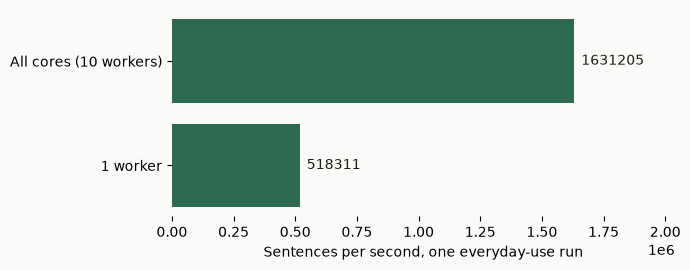

In [6]:
from IPython.display import Markdown, display
from _charts import speed_chart

run_info, speed = measure(encoder, source, sentence_count, work)
display(
    Markdown(
        "| Setting | Sentences/second | Sentences/minute | Load before | Load after |\n"
        "|---|---:|---:|---:|---:|\n"
        + "\n".join(
            f"| {r['setting']} | {r['sentences_per_second']:,.0f} | {r['sentences_per_minute']:,.0f} | "
            f"{r['load_before']:.2f} | {r['load_after']:.2f} |"
            for r in speed
        )
    )
)
speed_chart(speed)

Your results will depend on text length, machine, batch size, and other work running at the same time.
**Do not use this run to rank libraries** or infer a controlled speedup.
See the [performance guide](../PERFORMANCE.md) for measurements, methods, and their limits.
To encode a list that fits in memory, use `encoder.encode(texts)` as above, or stream lists through `encode_batches` as below.

## 5. Save the vectors to disk

A **sink** receives vectors as fse produces them.
`ShardSink` saves them in separate files, called shards, rather than keeping the full matrix in memory.
This pass saves all two million vectors as float32, which needs about 2 GB plus the text downloads.
Use one writer and a supported local filesystem, with at least 4 GB free for this recipe.

In [7]:
store_path = work / "wiki-vectors"
with fse.ShardSink(store_path, encoder, shard_rows=65536) as sink:
    for batch in encoder.encode_batches(text_batches(source), sink=sink):
        pass
print(f"Saved {sentence_count:,} vectors.")

Saved 2,000,000 vectors.


## 6. Search the stored sentences with fse

Open the store and encode your query with the same model.
**Search runs inside fse on the stored rows**, checking every row in exact mode with worker threads.
`k=5` requests five hits, `workers` controls thread count, and the [search API](../docs/architecture/store.md) also offers BLAS mode for larger query batches.
The results below show actual source text beside each score.

In [8]:
import os

with fse.VectorStore.open(store_path, encoder=encoder) as store:
    result = store.search(
        encoder.encode(["A spacecraft exploring the solar system"]),
        k=5,
        mode="exact",
        workers=os.process_cpu_count() or 1,
    )
    assert len(store) == sentence_count
    hits = read_hits(source, result.ids[0])
    for row_id, score in zip(result.ids[0], result.scores[0], strict=True):
        print(f"{score:.3f}  {hits[int(row_id)]}")

0.689  In the 1970s , two Helios spacecraft and the Skylab Apollo Telescope Mount provided scientists with significant new data on solar wind and the solar corona .
0.687  In 2003 , NASA conducted a conceptual study called " Human Outer Planets Exploration " ( HOPE ) regarding the future human exploration of the outer solar system .
0.686  It is expected that NASA 's Voyager spacecraft , as they pass the heliopause , will transmit valuable data on radiation levels and solar wind to Earth .
0.681  Since that time , unmanned spacecraft have successfully examined each of the Solar System 's planets , as well their moons and many minor planets and comets .
0.680  These probes make Jupiter the most visited of the Solar System 's outer planets as all missions to the outer Solar System have used Jupiter flybys to reduce fuel requirements and travel time .


## Result

You turned real text into vectors, compared sentence directions, and searched two million saved rows.
**The store returns row IDs**, so keep source texts or an ID-to-text table alongside a real application store.
The helper deletes this example store at cleanup, so choose your own permanent paths when adapting it.

## What next?

- [Continue a file job after an interruption](03-files-with-resume.ipynb), or [train a classifier](02-linear-heads.ipynb).
- [fse API and design](../docs/architecture/runtime.md)
- [Model card and license](https://huggingface.co/minishlab/potion-base-8M)

Back to the [recipe index](README.md) or the [main README](../README.md).

## Clean up

The helper keeps generated files in a temporary folder. Run this after you finish exploring the results.

In [9]:
recipe.close()